In [4]:
from IPython.display import HTML
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [5]:
# simple value object

# the __repr__ function is helping in printing out the values properly, without it we would get hex numbers when printing
class Value:
    def __init__(self, data, _children=(), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
        
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children = (self, other), _op = '+') 
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
        
    def __mul__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data * other.data, _children = (self, other), _op = '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')
        def _backward():
            self.grad +=  other * (self.data ** (other - 1)) * out.grad
            
        out._backward = _backward
        return out

    def __radd__(self, other): # for number + Value
        return self + other
    
    def __rmul__(self, other):    # other * self (swaps the order)
        return self * other

    def __truediv__(self, other):  # self / other
        return self * other**-1

    def __neg__(self):
        return self * -1 # - self

    def __sub__(self, other):  # self - other
        return self + (- other)
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t,(self, ),'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x),(self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad 
        out._backward = _backward
        return out
        
    def backward(self):
        # made the topological list
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0 # set the output grad to 1
        # go from the reversed order of the topological list
        for node in reversed(topo):
            node._backward()
            

In [6]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges
def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [7]:
# building neural networks for our micrograds -- Value objects
class Neuron:

    def __init__(self, nin): # takes in self and number of inputs to that specific neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        # print("weights ", self.w, "\n")
        self.b = Value(random.uniform(-1,1))
        # print("bias ", self.b, "\n")

    def __call__(self, x):
        # w * x + b
        # print("ziping ", list(zip(self.w, x))) # iterates over the tuples of the two iterators corresponding entries
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b) # sum can take in a second parameter, by default its 0.0 but we can just add the bias at the srart for efficiency
        out = act.tanh()
        # print("calculated the forward pass ",out)
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):  # (each neurons dimension, how many of them I want)
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
        
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


In [17]:
from sklearn.datasets import make_moons

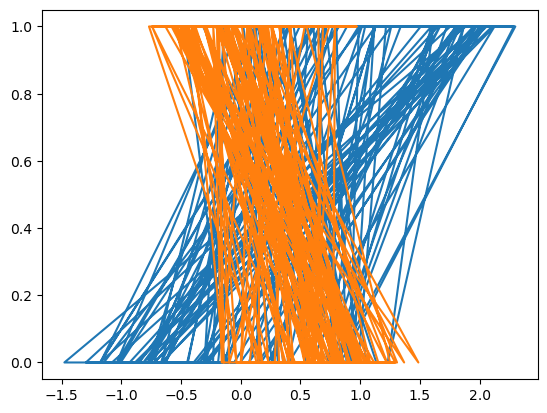

In [18]:
X, y = make_moons(n_samples = 200, noise = 0.2, random_state = 42)

plt.plot(X, y)
# print(X.shape[1])
# print(X)

In [19]:
n = MLP(X.shape[1], [5, 5, 4, 1]) # want X.shape[1] (number of rows) amount of inputs to each neurons
len(n.parameters())
y = y * 2 - 1 

In [22]:
epochs = 120
for k in range(epochs):
    # forward pass
    ypred = [n(x) for x in X]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(y,ypred)]) * (1.0/len(y))

    # backward pass
    for p in n.parameters():
        p.grad = 0.0 # always need to reset the gradients to zero for each backward pass
    loss.backward()

    # update
    for p in n.parameters():
        p.data += - 0.05 * p.grad

    if k%10 == 0: print(f'iteration {k} -- loss {loss.data}')
    

iteration 0 -- loss 0.23662530245701235
iteration 10 -- loss 0.22302126283883522
iteration 20 -- loss 0.20973282427363363
iteration 30 -- loss 0.19712962078767685
iteration 40 -- loss 0.185482091993836
iteration 50 -- loss 0.17493443967315178
iteration 60 -- loss 0.16551909523137698
iteration 70 -- loss 0.1571905723411465
iteration 80 -- loss 0.14985922692149678
iteration 90 -- loss 0.14341661873076955
iteration 100 -- loss 0.13775171962498886
iteration 110 -- loss 0.13275997060546846


In [23]:
ypred = [n(list(x)) for x in X]
preds = [1 if p.data > 0 else -1 for p in ypred]
accuracy = sum(int(p == yt) for p, yt in zip(preds, y)) / len(y)
print(f"accuracy: {accuracy:.2%}")

accuracy: 97.00%


In [24]:
# dot = draw_dot(loss)
# svg = dot.pipe(format='svg').decode('utf-8')

# HTML(f"""
# <div style="
#     width: 100%;
#     height: 800px;
#     overflow: auto;
# ">
#     <div style="width: 4000px;">
#         {svg}
#     </div>
# </div>
# """)

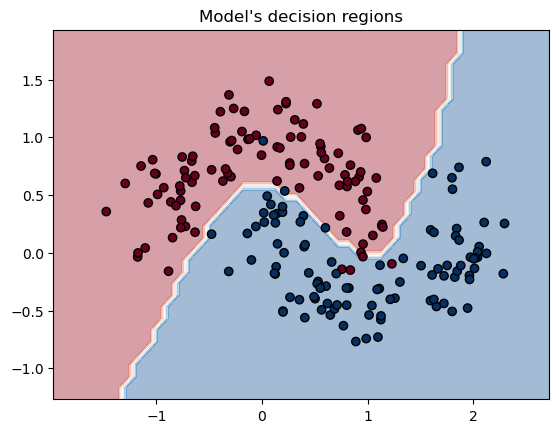

In [25]:
import numpy as np

step = 0.1
xx, yy = np.meshgrid(np.arange(X[:,0].min()-0.5, X[:,0].max()+0.5, step),
                     np.arange(X[:,1].min()-0.5, X[:,1].max()+0.5, step))
grid = np.c_[xx.ravel(), yy.ravel()]

scores = np.array([n(list(pt)).data for pt in grid])
zz = (scores > 0).astype(int).reshape(xx.shape)   # 1 if model says class 1, else 0

plt.contourf(xx, yy, zz, alpha=0.4, cmap='RdBu')
plt.scatter(X[:,0], X[:,1], c=y, cmap='RdBu', edgecolors='k')
plt.title("Model's decision regions")
plt.show()